# 🤖 Deep Q-Learning (DQN) — Hands-On Tutorial


---

## 🎯 What We Will Build
We will train a **DQN agent** to balance a pole on a cart using **PyTorch** and **OpenAI Gymnasium**.  
By the end, your agent should balance the pole for **500 consecutive steps** — the solved threshold.

## 🗺️ Notebook Roadmap
| Section | What You Learn |
|---------|----------------|
| 1. Setup | Install libs, import dependencies |
| 2. Environment | Explore CartPole state/action/reward |
| 3. Neural Network | Build the Q-network in PyTorch |
| 4. Replay Buffer | Store and sample experience |
| 5. Agent | ε-greedy policy + action selection |
| 6. Training | Full DQN training loop |
| 7. Evaluation | Test and visualize results |
| 8. Experiments | Tune hyperparameters yourself |

---
## Section 1 — Setup & Installation

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Install required libraries
#  gymnasium  : environment (CartPole-v1)
#  torch      : neural network + autograd
#  matplotlib : plotting training curves
# ─────────────────────────────────────────────────────────────────
!pip install gymnasium torch matplotlib --quiet
print('✅ All packages installed!')

✅ All packages installed!


In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Standard library imports
# ─────────────────────────────────────────────────────────────────
import gymnasium as gym        # RL environments
import numpy as np             # numerical arrays
import torch                   # deep learning framework
import torch.nn as nn          # neural network layers
import torch.optim as optim    # optimizers (Adam)
import random                  # for epsilon-greedy randomness
import matplotlib.pyplot as plt
from collections import deque  # fast FIFO buffer
from IPython.display import clear_output

# ── Reproducibility ──────────────────────────────────────────────
# Setting seeds ensures your results can be reproduced by others.
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# ── Device selection ─────────────────────────────────────────────
# If a GPU is available (Colab T4), PyTorch will use it automatically.
# On CPU this still trains fine — CartPole is a small problem.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🖥️  Using device: {device}')

🖥️  Using device: cpu


---
## Section 2 — Explore the CartPole Environment

Before training, always explore your environment!

**CartPole-v1:**
- **State**: 4 floats — [cart position, cart velocity, pole angle, pole angular velocity]
- **Actions**: 2 discrete — 0 (push left), 1 (push right)
- **Reward**: +1 for every step the pole stays upright
- **Done**: pole angle > 12°, cart position > 2.4, or step > 500

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Create the environment and inspect its properties
# ─────────────────────────────────────────────────────────────────
env = gym.make('CartPole-v1')

# These two values are crucial for building our neural network:
#   state_dim  → number of inputs to the Q-network
#   action_dim → number of outputs (one Q-value per action)
state_dim  = env.observation_space.shape[0]   # = 4
action_dim = env.action_space.n               # = 2

print(f'📦 State space dimension : {state_dim}')
print(f'🕹️  Action space size     : {action_dim}')
print(f'🔍 State space bounds    : {env.observation_space.low} to {env.observation_space.high}')

📦 State space dimension : 4
🕹️  Action space size     : 2
🔍 State space bounds    : [-4.8               -inf -0.41887903        -inf] to [4.8               inf 0.41887903        inf]


In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Run ONE random episode to see what the env looks like
#  A random agent takes random actions — this is our baseline.
# ─────────────────────────────────────────────────────────────────
state, _ = env.reset(seed=SEED)   # reset returns (obs, info)
total_reward = 0
step = 0

while True:
    action = env.action_space.sample()   # completely random action
    next_state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    step += 1
    done = terminated or truncated
    state = next_state
    if done:
        break

print(f'🎲 Random agent lasted {step} steps with total reward {total_reward}')
print('   (Our DQN agent should reach ~500 steps!)')

🎲 Random agent lasted 16 steps with total reward 16.0
   (Our DQN agent should reach ~500 steps!)


---
## Section 3 — Build the Q-Network

The Q-network is a simple **feed-forward neural network** that:
- **Input**: state vector (4 numbers)
- **Hidden layers**: 2 layers of 128 neurons with ReLU activation
- **Output**: Q-value for each action (2 numbers)

```
State (4) → [128] → ReLU → [128] → ReLU → Q-values (2)
```

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  DQN Network Definition
#  We use nn.Module — PyTorch's base class for all neural networks.
# ─────────────────────────────────────────────────────────────────
class DQN(nn.Module):
    """
    Deep Q-Network: maps state → Q-values for each action.

    Architecture: Linear → ReLU → Linear → ReLU → Linear
    The output layer has NO activation (raw Q-values, can be negative).
    """

    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 128):
        """
        Args:
            state_dim  : size of input (observation space)
            action_dim : number of actions (output neurons)
            hidden_dim : neurons per hidden layer (default 128)
        """
        super(DQN, self).__init__()

        # Sequential wraps layers into a pipeline: input → fc1 → relu → fc2 → relu → fc3
        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),   # layer 1: state → hidden
            nn.ReLU(),                           # non-linearity (kills negatives)
            nn.Linear(hidden_dim, hidden_dim),  # layer 2: hidden → hidden
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim),  # layer 3: hidden → Q-values
            # NO activation here — Q-values can be any real number
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass: given state tensor x, return Q-values.
        Called automatically when you do: model(state_tensor)
        """
        return self.network(x)


# ── Quick test: confirm network shape is correct ─────────────────
test_net = DQN(state_dim, action_dim)
dummy_state = torch.zeros(1, state_dim)          # batch of 1 state
dummy_output = test_net(dummy_state)
print(f'✅ Network input  shape: {dummy_state.shape}')   # (1, 4)
print(f'✅ Network output shape: {dummy_output.shape}')  # (1, 2)
print(f'   (One Q-value per action, makes sense!)')
print(f'\n📊 Network architecture:')
print(test_net)

✅ Network input  shape: torch.Size([1, 4])
✅ Network output shape: torch.Size([1, 2])
   (One Q-value per action, makes sense!)

📊 Network architecture:
DQN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


---
## Section 4 — Replay Buffer (Experience Replay)

**Why do we need this?**
- Normal online training uses consecutive (s, a, r, s') — these are **highly correlated**
- Correlated samples make gradient updates noisy and unstable
- Solution: store transitions in a buffer and **sample randomly**

**How it works:**
1. Every step → push (s, a, r, s', done) into the buffer
2. When buffer is large enough → sample a random mini-batch
3. Train on that mini-batch (decorrelated!)

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Replay Buffer
#  Uses collections.deque with a max length — oldest items auto-drop.
# ─────────────────────────────────────────────────────────────────
class ReplayBuffer:
    """
    Fixed-size circular buffer that stores experience tuples.
    Supports random sampling for decorrelated training.
    """

    def __init__(self, capacity: int):
        """
        Args:
            capacity: maximum number of transitions to store
                      When full, oldest transitions are discarded.
        """
        # deque with maxlen automatically drops oldest items when full
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        """Store one transition (s, a, r, s', done) in the buffer."""
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int):
        """
        Randomly sample a mini-batch of transitions.
        Returns tensors ready for neural network training.
        """
        # random.sample draws WITHOUT replacement — no duplicates
        batch = random.sample(self.buffer, batch_size)

        # Unzip list of tuples into separate arrays for each component
        states, actions, rewards, next_states, dones = zip(*batch)

        # Convert to PyTorch tensors and move to the right device (CPU/GPU)
        return (
            torch.FloatTensor(np.array(states)).to(device),      # (B, state_dim)
            torch.LongTensor(actions).to(device),                 # (B,)
            torch.FloatTensor(rewards).to(device),                # (B,)
            torch.FloatTensor(np.array(next_states)).to(device),  # (B, state_dim)
            torch.FloatTensor(dones).to(device),                  # (B,) — 1.0 if done
        )

    def __len__(self):
        """Return current buffer size (needed to check if we can start training)."""
        return len(self.buffer)


# ── Test buffer ──────────────────────────────────────────────────
test_buf = ReplayBuffer(capacity=100)
for _ in range(10):
    test_buf.push(
        state=np.zeros(4), action=0, reward=1.0,
        next_state=np.ones(4), done=False
    )
s, a, r, s2, d = test_buf.sample(5)
print(f'✅ Buffer test passed!')
print(f'   States shape    : {s.shape}')   # (5, 4)
print(f'   Actions shape   : {a.shape}')   # (5,)
print(f'   Rewards shape   : {r.shape}')   # (5,)

✅ Buffer test passed!
   States shape    : torch.Size([5, 4])
   Actions shape   : torch.Size([5])
   Rewards shape   : torch.Size([5])


---
## Section 5 — Hyperparameters & Agent Setup

All hyperparameters are collected in one place — good practice!  
**Try changing these in Section 8 (Experiments).**

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Hyperparameters — change these to experiment!
# ─────────────────────────────────────────────────────────────────

# Replay buffer
BUFFER_CAPACITY = 10_000   # max transitions stored (older ones discarded)
BATCH_SIZE      = 64       # transitions sampled per training step

# Learning
GAMMA = 0.99               # discount factor: 0 = myopic, 1 = long-sighted
LR    = 1e-4               # Adam learning rate

# Epsilon-greedy exploration
EPS_START = 1.0            # start fully random (explore everything at first)
EPS_END   = 0.01           # minimum: always keep 1% exploration
EPS_DECAY = 0.995          # multiply epsilon by this each episode

# Training duration
NUM_EPISODES  = 500        # total training episodes
TARGET_UPDATE = 10         # sync target network every N episodes

# ─────────────────────────────────────────────────────────────────
#  Create networks and optimizer
# ─────────────────────────────────────────────────────────────────

# ONLINE network: this is updated at every training step via backprop
online_net = DQN(state_dim, action_dim).to(device)

# TARGET network: copy of online_net, updated only every TARGET_UPDATE episodes
# This "stabilizes" learning by keeping the learning target fixed for a while.
target_net = DQN(state_dim, action_dim).to(device)
target_net.load_state_dict(online_net.state_dict())  # start with same weights
target_net.eval()   # target net is NEVER trained directly — only copied into

# Adam optimizer for the online network
optimizer = optim.Adam(online_net.parameters(), lr=LR)

# Loss function: Mean Squared Error between predicted and target Q-values
criterion = nn.MSELoss()

# Replay buffer
replay_buffer = ReplayBuffer(capacity=BUFFER_CAPACITY)

print('✅ Networks, optimizer, and buffer created!')
print(f'   Online net params : {sum(p.numel() for p in online_net.parameters()):,}')

✅ Networks, optimizer, and buffer created!
   Online net params : 17,410


---
## Section 6 — Core DQN Functions

We define three key functions:
1. **`select_action`** — ε-greedy action selection
2. **`train_step`** — one gradient update from a mini-batch
3. **`sync_target`** — copy online → target network

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  1. ε-Greedy Action Selection
# ─────────────────────────────────────────────────────────────────
def select_action(state: np.ndarray, epsilon: float) -> int:
    """
    Choose an action using the epsilon-greedy strategy.

    With probability ε → EXPLORE: pick a random action
    With probability 1-ε → EXPLOIT: pick argmax Q(s,a)

    Args:
        state   : current environment observation (numpy array)
        epsilon : current exploration rate (0.0 to 1.0)

    Returns:
        action (int): 0 = push left, 1 = push right
    """
    if random.random() < epsilon:
        # EXPLORE: random action (ignores the neural network)
        return env.action_space.sample()
    else:
        # EXPLOIT: forward pass through Q-network → pick highest Q-value action
        with torch.no_grad():   # no_grad = skip gradient computation (saves memory)
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)  # (1, 4)
            q_values = online_net(state_tensor)   # (1, 2) — Q-value for each action
            return q_values.argmax(dim=1).item()  # action with highest Q-value


# ─────────────────────────────────────────────────────────────────
#  2. Training Step — one mini-batch gradient update
# ─────────────────────────────────────────────────────────────────
def train_step() -> float:
    """
    Sample a mini-batch from the replay buffer and perform one
    gradient descent step on the online network.

    DQN loss = MSE( TD_target , Q_online(s,a) )
    TD_target = r + γ * max_a' Q_target(s', a')   [if not done]
    TD_target = r                                  [if done — no future]

    Returns:
        loss (float): scalar loss value for logging
    """
    # Don't train until we have enough samples
    if len(replay_buffer) < BATCH_SIZE:
        return 0.0

    # ── 1. Sample random mini-batch ──────────────────────────────
    states, actions, rewards, next_states, dones = replay_buffer.sample(BATCH_SIZE)

    # ── 2. Compute current Q-values Q(s, a) ──────────────────────
    # online_net outputs Q for ALL actions; we select only the taken action.
    # gather(1, actions.unsqueeze(1)) picks the Q-value of the chosen action.
    current_q = online_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)  # (B,)

    # ── 3. Compute TD target using TARGET network ─────────────────
    with torch.no_grad():
        # max Q-value from next state (greedy)
        next_q_max = target_net(next_states).max(dim=1)[0]   # (B,)

        # If episode ended (done=1), there is NO future reward.
        # (1 - dones) masks out future Q for terminal states.
        td_target = rewards + GAMMA * next_q_max * (1.0 - dones)   # (B,)

    # ── 4. Compute loss and backpropagate ─────────────────────────
    loss = criterion(current_q, td_target)   # MSE between predicted and target
    optimizer.zero_grad()    # clear old gradients
    loss.backward()          # compute gradients (backpropagation)

    # Gradient clipping prevents exploding gradients (optional but recommended)
    nn.utils.clip_grad_norm_(online_net.parameters(), max_norm=1.0)

    optimizer.step()         # update weights using computed gradients
    return loss.item()       # return scalar loss for logging


# ─────────────────────────────────────────────────────────────────
#  3. Sync Target Network
# ─────────────────────────────────────────────────────────────────
def sync_target():
    """
    Copy online network weights into the target network.
    Called every TARGET_UPDATE episodes.
    This is the 'hard update' strategy.
    """
    target_net.load_state_dict(online_net.state_dict())


print('✅ Core DQN functions defined!')
print('   - select_action(state, epsilon)')
print('   - train_step() → loss')
print('   - sync_target()')

✅ Core DQN functions defined!
   - select_action(state, epsilon)
   - train_step() → loss
   - sync_target()


---
## Section 7 — Full Training Loop

Now we put everything together into the main training loop.

**Per episode:**
1. Reset environment → get initial state
2. Loop through timesteps:
   - Select action (ε-greedy)
   - Execute in environment → (reward, next_state, done)
   - Store in replay buffer
   - Sample mini-batch → train step
3. Decay epsilon
4. Every N episodes → sync target network
5. Log & plot progress

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Training Loop
# ─────────────────────────────────────────────────────────────────
episode_rewards = []    # store total reward per episode
episode_losses  = []    # store average loss per episode
epsilon = EPS_START     # start with full exploration

print('🚀 Starting DQN training...')
print(f'   Episodes: {NUM_EPISODES} | Batch: {BATCH_SIZE} | γ={GAMMA} | LR={LR}')
print('-' * 60)

for episode in range(1, NUM_EPISODES + 1):

    # ── Reset environment ────────────────────────────────────────
    state, _ = env.reset()
    total_reward = 0.0
    episode_loss = []

    # ── Run one episode ──────────────────────────────────────────
    while True:

        # 1. Select action using ε-greedy policy
        action = select_action(state, epsilon)

        # 2. Take action in environment
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # 3. Store transition in replay buffer
        replay_buffer.push(state, action, reward, next_state, float(done))

        # 4. Perform one training step (if buffer is large enough)
        loss = train_step()
        if loss > 0:
            episode_loss.append(loss)

        # 5. Move to next state
        total_reward += reward
        state = next_state

        if done:
            break  # episode over

    # ── Post-episode bookkeeping ─────────────────────────────────

    # Record metrics
    episode_rewards.append(total_reward)
    avg_loss = np.mean(episode_loss) if episode_loss else 0.0
    episode_losses.append(avg_loss)

    # Decay epsilon (reduce exploration over time)
    epsilon = max(EPS_END, epsilon * EPS_DECAY)

    # Sync target network every TARGET_UPDATE episodes
    if episode % TARGET_UPDATE == 0:
        sync_target()

    # ── Progress logging every 25 episodes ───────────────────────
    if episode % 25 == 0:
        avg_reward = np.mean(episode_rewards[-25:])  # last 25 episodes
        print(f'Ep {episode:4d} | Avg Reward: {avg_reward:6.1f} | '
              f'ε={epsilon:.3f} | Loss={avg_loss:.4f} | '
              f'Buffer={len(replay_buffer):5d}')

        # Check if solved
        if avg_reward >= 475:
            print(f'\n🎉 SOLVED at episode {episode}! Avg reward ≥ 475 over last 25 episodes.')
            break

print('\n✅ Training complete!')

🚀 Starting DQN training...
   Episodes: 500 | Batch: 64 | γ=0.99 | LR=0.0001
------------------------------------------------------------
Ep   25 | Avg Reward:   20.0 | ε=0.882 | Loss=0.0928 | Buffer=  500
Ep   50 | Avg Reward:   18.2 | ε=0.778 | Loss=0.3237 | Buffer=  955
Ep   75 | Avg Reward:   30.8 | ε=0.687 | Loss=0.6839 | Buffer= 1724
Ep  100 | Avg Reward:   44.7 | ε=0.606 | Loss=0.7384 | Buffer= 2841
Ep  125 | Avg Reward:   85.8 | ε=0.534 | Loss=1.5341 | Buffer= 4985
Ep  150 | Avg Reward:   99.7 | ε=0.471 | Loss=1.0408 | Buffer= 7477
Ep  175 | Avg Reward:  167.7 | ε=0.416 | Loss=0.9618 | Buffer=10000
Ep  200 | Avg Reward:  179.7 | ε=0.367 | Loss=0.8376 | Buffer=10000
Ep  225 | Avg Reward:  217.6 | ε=0.324 | Loss=0.6740 | Buffer=10000
Ep  250 | Avg Reward:  197.7 | ε=0.286 | Loss=0.7628 | Buffer=10000
Ep  275 | Avg Reward:  203.1 | ε=0.252 | Loss=1.2132 | Buffer=10000
Ep  300 | Avg Reward:  193.5 | ε=0.222 | Loss=1.1125 | Buffer=10000
Ep  325 | Avg Reward:  173.2 | ε=0.196 | Loss=

---
## Section 8 — Visualize Training Results

NameError: name 'episode_rewards' is not defined

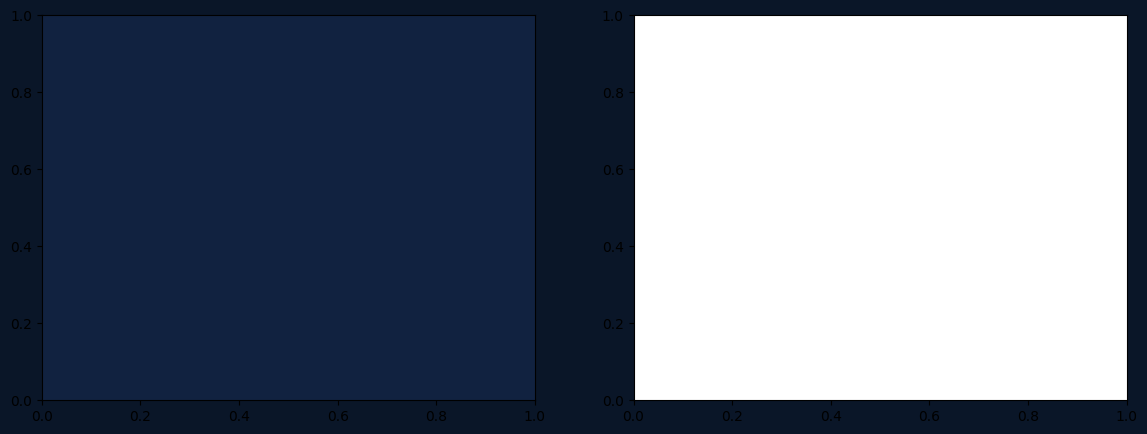

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Plot reward and loss curves
# ─────────────────────────────────────────────────────────────────
def smooth(data, window=20):
    """Running average to smooth noisy curves for better visibility."""
    return np.convolve(data, np.ones(window)/window, mode='valid')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0A1628')

# ── Reward curve ─────────────────────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#112240')
ax1.plot(episode_rewards, alpha=0.3, color='#90E0EF', linewidth=0.8, label='Raw reward')
if len(episode_rewards) >= 20:
    ax1.plot(range(19, len(episode_rewards)), smooth(episode_rewards),
             color='#00B4D8', linewidth=2, label='Smoothed (20-ep avg)')
ax1.axhline(y=475, color='#4CAF50', linestyle='--', alpha=0.8, label='Solved threshold (475)')
ax1.set_xlabel('Episode', color='white')
ax1.set_ylabel('Total Reward', color='white')
ax1.set_title('Training Reward over Episodes', color='white', fontsize=13, fontweight='bold')
ax1.tick_params(colors='white')
ax1.legend(facecolor='#0A1628', labelcolor='white')
ax1.spines[:].set_color('#1A3A5C')

# ── Loss curve ────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#112240')
ax2.plot(episode_losses, alpha=0.3, color='#FF9800', linewidth=0.8, label='Raw loss')
if len(episode_losses) >= 20:
    ax2.plot(range(19, len(episode_losses)), smooth(episode_losses),
             color='#FF9800', linewidth=2, label='Smoothed')
ax2.set_xlabel('Episode', color='white')
ax2.set_ylabel('MSE Loss', color='white')
ax2.set_title('Training Loss over Episodes', color='white', fontsize=13, fontweight='bold')
ax2.tick_params(colors='white')
ax2.legend(facecolor='#0A1628', labelcolor='white')
ax2.spines[:].set_color('#1A3A5C')

plt.tight_layout()
plt.savefig('dqn_training_curves.png', dpi=150, bbox_inches='tight', facecolor='#0A1628')
plt.show()
print('📊 Training curves saved as dqn_training_curves.png')

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Evaluate the trained agent (no exploration, pure exploitation)
# ─────────────────────────────────────────────────────────────────
def evaluate(n_episodes: int = 10) -> float:
    """
    Run n_episodes with epsilon=0 (full exploitation) and
    return the average reward.
    """
    online_net.eval()    # switch to eval mode (disables dropout etc.)
    rewards = []

    for ep in range(n_episodes):
        state, _ = env.reset()
        total = 0.0
        while True:
            action = select_action(state, epsilon=0.0)   # pure greedy
            state, reward, terminated, truncated, _ = env.step(action)
            total += reward
            if terminated or truncated:
                break
        rewards.append(total)

    online_net.train()   # switch back to train mode
    return np.mean(rewards), np.std(rewards)


mean_r, std_r = evaluate(n_episodes=20)
print(f'📊 Evaluation over 20 episodes:')
print(f'   Mean reward : {mean_r:.1f}')
print(f'   Std  reward : {std_r:.1f}')

if mean_r >= 475:
    print('\n🏆 Agent has SOLVED CartPole-v1!')
else:
    print(f'\n📈 Agent reached {mean_r:.1f}/500. Try more episodes or tune hyperparameters.')

📊 Evaluation over 20 episodes:
   Mean reward : 500.0
   Std  reward : 0.0

🏆 Agent has SOLVED CartPole-v1!


---
## Section 9 — Experiments: Tune the Hyperparameters

Try changing one hyperparameter at a time and observe the effect.  
Fill in the table after each run:

| Experiment | GAMMA | LR | EPS_DECAY | Episodes to Solve |
|-----------|-------|-----|-----------|-------------------|
| Baseline  | 0.99  | 1e-4 | 0.995   | ? |
| Low gamma | 0.90  | 1e-4 | 0.995   | ? |
| High LR   | 0.99  | 5e-4 | 0.995   | ? |
| Fast decay| 0.99  | 1e-4 | 0.99    | ? |

Running baseline (γ=0.99)...
Running low gamma (γ=0.90)...


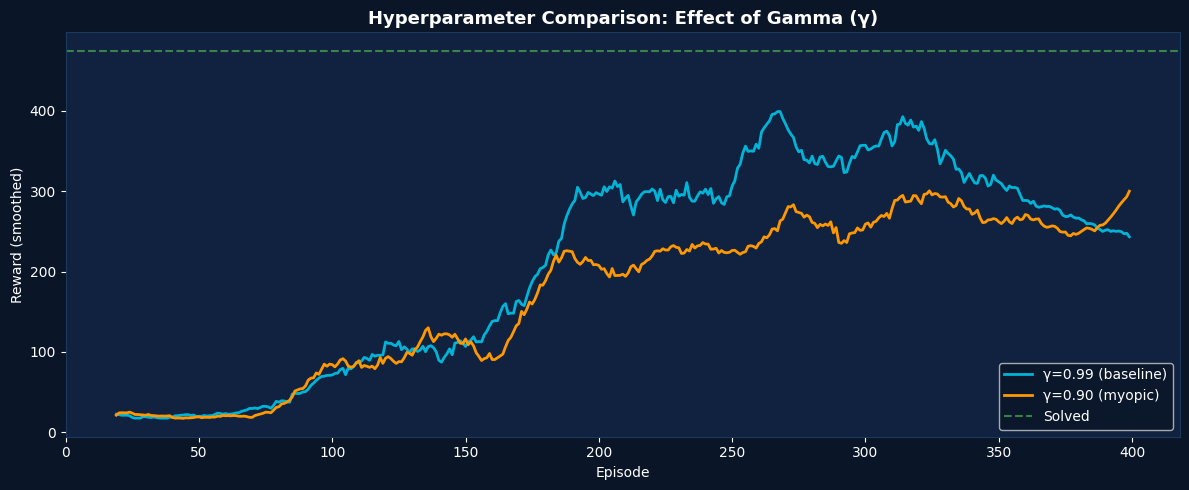

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Convenience function: train from scratch with custom params
#  Call this cell to run your own experiment!
# ─────────────────────────────────────────────────────────────────
def run_experiment(gamma=0.99, lr=1e-4, eps_decay=0.995,
                   num_episodes=400, batch_size=64,
                   label='experiment'):
    """
    Train a fresh DQN agent with given hyperparameters.
    Returns: list of episode rewards.
    """
    # Fresh networks
    net    = DQN(state_dim, action_dim).to(device)
    t_net  = DQN(state_dim, action_dim).to(device)
    t_net.load_state_dict(net.state_dict())
    t_net.eval()
    opt    = optim.Adam(net.parameters(), lr=lr)
    buf    = ReplayBuffer(10_000)
    eps    = 1.0
    rews   = []

    for ep in range(1, num_episodes + 1):
        state, _ = env.reset()
        total = 0.0
        while True:
            # ε-greedy
            if random.random() < eps:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    st = torch.FloatTensor(state).unsqueeze(0).to(device)
                    action = net(st).argmax(1).item()

            ns, r, ter, trun, _ = env.step(action)
            done = ter or trun
            buf.push(state, action, r, ns, float(done))
            total += r
            state = ns

            # Train step
            if len(buf) >= batch_size:
                ss, aa, rr, ss2, dd = buf.sample(batch_size)
                cq = net(ss).gather(1, aa.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    tq = r + gamma * t_net(ss2).max(1)[0] * (1-dd)
                loss = nn.MSELoss()(cq, tq)
                opt.zero_grad(); loss.backward(); opt.step()

            if done: break

        rews.append(total)
        eps = max(0.01, eps * eps_decay)
        if ep % TARGET_UPDATE == 0:
            t_net.load_state_dict(net.state_dict())

    return rews


# ── Run two experiments and compare ──────────────────────────────
print('Running baseline (γ=0.99)...')
r1 = run_experiment(gamma=0.99, label='γ=0.99 (baseline)')
print('Running low gamma (γ=0.90)...')
r2 = run_experiment(gamma=0.90, label='γ=0.90 (myopic)')

# Plot comparison
plt.figure(figsize=(12, 5), facecolor='#0A1628')
ax = plt.gca()
ax.set_facecolor('#112240')
if len(r1) >= 20:
    ax.plot(range(19, len(r1)), smooth(r1), color='#00B4D8', linewidth=2, label='γ=0.99 (baseline)')
if len(r2) >= 20:
    ax.plot(range(19, len(r2)), smooth(r2), color='#FF9800', linewidth=2, label='γ=0.90 (myopic)')
ax.axhline(475, color='#4CAF50', linestyle='--', alpha=0.7, label='Solved')
ax.set_xlabel('Episode', color='white'); ax.set_ylabel('Reward (smoothed)', color='white')
ax.set_title('Hyperparameter Comparison: Effect of Gamma (γ)', color='white', fontsize=13, fontweight='bold')
ax.tick_params(colors='white'); ax.legend(facecolor='#0A1628', labelcolor='white')
ax.spines[:].set_color('#1A3A5C')
plt.tight_layout()
plt.savefig('dqn_experiment_comparison.png', dpi=150, bbox_inches='tight', facecolor='#0A1628')
plt.show()

---
## Section 10 — Bonus: Save & Load Your Agent

In [ ]:
# ─────────────────────────────────────────────────────────────────
#  Save trained model weights to disk
#  In Colab, download from the Files panel (left sidebar).
# ─────────────────────────────────────────────────────────────────
torch.save(online_net.state_dict(), 'dqn_cartpole.pth')
print('💾 Model saved as dqn_cartpole.pth')

# Load it back
loaded_net = DQN(state_dim, action_dim).to(device)
loaded_net.load_state_dict(torch.load('dqn_cartpole.pth', map_location=device))
loaded_net.eval()
print('📂 Model loaded successfully!')

# ─────────────────────────────────────────────────────────────────
#  Discussion Questions for Students
# ─────────────────────────────────────────────────────────────────
print("""
╔══════════════════════════════════════════════════════════════╗
║  🤔 Discussion Questions                                     ║
╠══════════════════════════════════════════════════════════════╣
║  1. What happens if you set ε=0 from the start?              ║
║     (Hint: the agent never explores!)                        ║
║                                                              ║
║  2. What if BUFFER_CAPACITY is very small (e.g., 100)?       ║
║     (Hint: less diversity in training batches)               ║
║                                                              ║
║  3. What happens with TARGET_UPDATE = 1?                     ║
║     (Hint: target always equals online = unstable)           ║
║                                                              ║
║  4. What if GAMMA = 0?                                       ║
║     (Hint: agent ignores all future — only cares about r)    ║
║                                                              ║
║  5. How would you extend this to Atari Pong?                 ║
║     (Hint: CNN encoder for pixel inputs)                     ║
╚══════════════════════════════════════════════════════════════╝
""")

💾 Model saved as dqn_cartpole.pth
📂 Model loaded successfully!

╔══════════════════════════════════════════════════════════════╗
║  🤔 Discussion Questions                                     ║
╠══════════════════════════════════════════════════════════════╣
║  1. What happens if you set ε=0 from the start?              ║
║     (Hint: the agent never explores!)                        ║
║                                                              ║
║  2. What if BUFFER_CAPACITY is very small (e.g., 100)?       ║
║     (Hint: less diversity in training batches)               ║
║                                                              ║
║  3. What happens with TARGET_UPDATE = 1?                     ║
║     (Hint: target always equals online = unstable)           ║
║                                                              ║
║  4. What if GAMMA = 0?                                       ║
║     (Hint: agent ignores all future — only cares about r)    ║
║                          